# Predicting Patient Death with Data Mining (SUPPORT2 Dataset)

**Problem:** Using information collected when a seriously ill patient enters the hospital, predict whether the patient dies during the follow-up period (`death`: 1 = died, 0 = survived).

**Dataset:** SUPPORT2 – UCI Machine Learning Repository (#880), 9,105 patients, 48 columns.

**Steps:** Load data → remove leakage columns → EDA → drop very empty columns → train/test split → outliers (IQR) → missing values → encoding → scaling → modeling (GridSearchCV, 5-fold) → evaluation.

## 1. Libraries

In [1]:
# Kullanılacak kütüphaneleri yükle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, roc_curve, matthews_corrcoef, cohen_kappa_score, balanced_accuracy_score
warnings.filterwarnings("ignore")

## 2. Load the data and define the target

Meaning of some important columns:

| Column | Meaning |
|---|---|
| `age`, `sex`, `race`, `edu`, `income` | Patient demographics |
| `dzgroup`, `dzclass` | Disease group / disease class (e.g. lung cancer, cirrhosis, ARF/MOSF) |
| `num.co` | Number of other diseases (comorbidities) |
| `ca` | Cancer status (no / yes / metastatic) |
| `scoma` | Coma score (higher = deeper coma) |
| `sps`, `aps` | Physiology / acute illness severity scores on day 3 |
| `prg2m`, `prg6m` | The doctor's estimate (day 3) that the patient survives 2 / 6 months |
| `adls`, `adlsc` | Daily-living activity scores (how dependent the patient is) |
| `meanbp`, `hrt`, `resp`, `temp` | Blood pressure, heart rate, breathing rate, temperature |
| `wblc`, `alb`, `bili`, `crea`, `sod`, `ph`, `glucose`, `bun`, `pafi` | Blood test results |
| `death` | **Target:** 1 = died during follow-up, 0 = survived |

In [2]:
# Veriyi oku, hedef sütunu (death) 0/1 tam sayı yap ve sınıf dağılımına bak
data = pd.read_csv("data/support2.csv")
print("Rows, columns:", data.shape)
data["death"] = data["death"].astype(int)
print(data["death"].value_counts())
print(data["death"].value_counts(normalize=True).round(3))

Rows, columns: (9105, 48)
death
1    6201
0    2904
Name: count, dtype: int64
death
1    0.681
0    0.319
Name: proportion, dtype: float64


## 3. Remove data leakage columns

These columns are learned **after** the outcome is known (or are an ID / another model's prediction). If we keep them, the model "cheats".

| Column | Why it is removed |
|---|---|
| `id` | Patient ID, no information |
| `hospdead` | Death in hospital – part of the outcome itself |
| `d.time` | Days of follow-up – ends when the patient dies |
| `slos` | Days until discharge – known only at the end of the stay |
| `charges`, `totcst`, `totmcst` | Total hospital costs – known only at the end of the stay |
| `avtisst` | Average treatment score over days 3–25 – collected after entry |
| `sfdm2` | Functional status at 2 months – one level is "died before 2 months" |
| `dnr`, `dnrday` | Do-not-resuscitate order and its day – often given near death |
| `surv2m`, `surv6m` | Survival estimates of the original SUPPORT model, which was trained on these same outcomes |

In [3]:
# Hedef belli olduktan sonra öğrenilen (sızıntı yapan) sütunları veri setinden at
leakage_columns = ["id", "hospdead", "d.time", "slos", "charges", "totcst", "totmcst", "avtisst", "sfdm2", "dnr", "dnrday", "surv2m", "surv6m"]
data = data.drop(columns=leakage_columns)
print("Remaining columns:", data.shape[1])
data.head()

Remaining columns: 35


,age,death,sex,dzgroup,dzclass,num.co,edu,income,scoma,race,...,bili,crea,sod,ph,glucose,bun,urine,adlp,adls,adlsc
0,62.84998,0,male,Lung Cancer,Cancer,0,11.0,$11-$25k,0.0,other,...,0.199982,1.199951,141.0,7.459961,NaN,NaN,NaN,7.0,7.0,7.0
1,60.33899,1,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,$11-$25k,44.0,white,...,NaN,5.500000,132.0,7.250000,NaN,NaN,NaN,NaN,1.0,1.0
2,52.74698,1,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,under $11k,0.0,white,...,2.199707,2.000000,134.0,7.459961,NaN,NaN,NaN,1.0,0.0,0.0
3,42.38498,1,female,Lung Cancer,Cancer,2,11.0,under $11k,0.0,white,...,NaN,0.799927,139.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0
4,79.88495,0,female,ARF/MOSF w/Sepsis,ARF/MOSF,1,NaN,NaN,26.0,white,...,NaN,0.799927,143.0,7.509766,NaN,NaN,NaN,NaN,2.0,2.0


## 4. Exploratory Data Analysis (EDA)

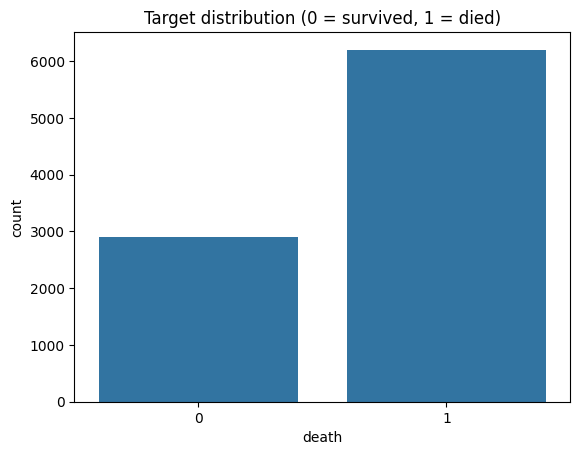

In [4]:
# Hedef değişkenin dağılımını çiz (sınıflar dengeli mi?)
sns.countplot(x="death", data=data)
plt.title("Target distribution (0 = survived, 1 = died)")
plt.show()

adlp       62.0
urine      53.4
glucose    49.4
bun        47.8
alb        37.0
income     32.8
adls       31.5
bili       28.6
pafi       25.5
ph         25.1
prg2m      18.1
edu        17.9
prg6m      17.9
wblc        2.3
crea        0.7
race        0.5
sps         0.0
aps         0.0
scoma       0.0
resp        0.0
temp        0.0
meanbp      0.0
hrt         0.0
sod         0.0
dtype: float64


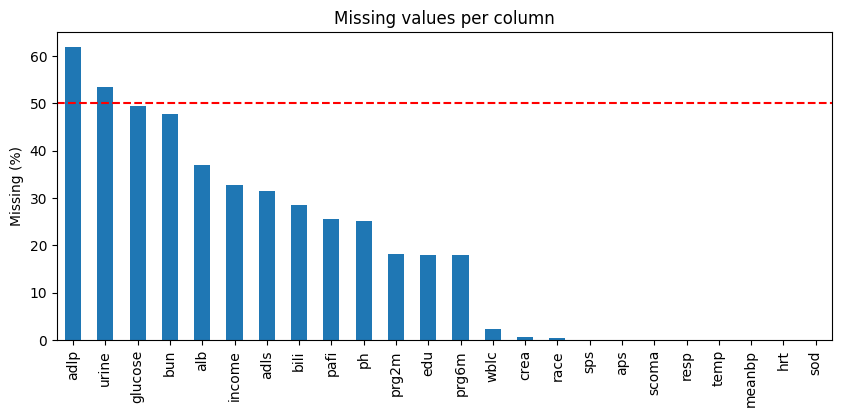

In [5]:
# Her sütundaki eksik değer yüzdesini çiz (kırmızı çizgi = %50 sınırı)
missing_percent = data.isnull().mean() * 100
missing_percent = missing_percent[missing_percent > 0].sort_values(ascending=False)
print(missing_percent.round(1))
missing_percent.plot(kind="bar", figsize=(10, 4))
plt.axhline(50, color="red", linestyle="--")
plt.ylabel("Missing (%)")
plt.title("Missing values per column")
plt.show()

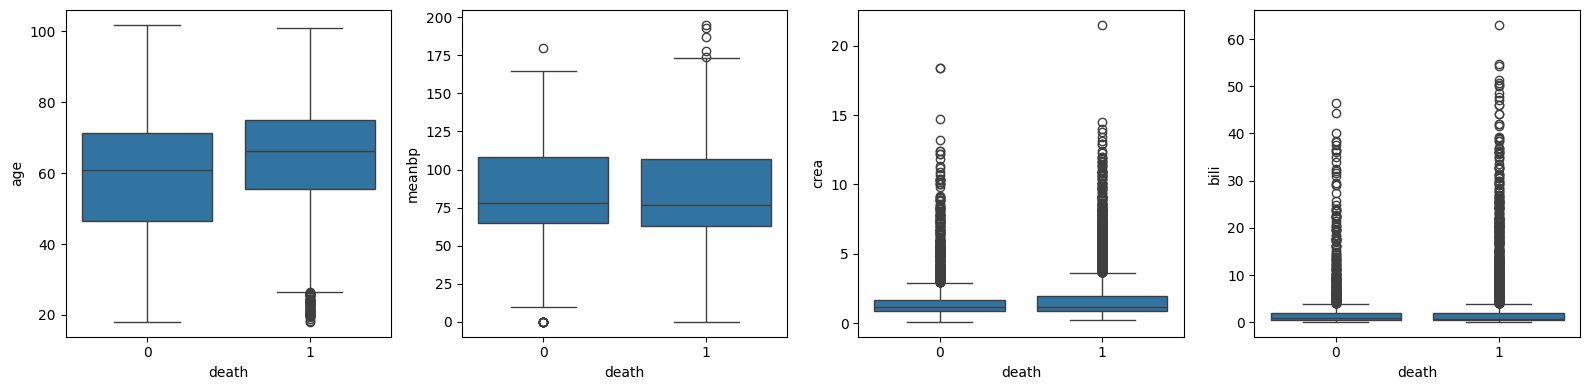

In [6]:
# Bazı sayısal sütunların hedefe göre kutu grafikleri (aykırı değerleri görmek için)
boxplot_columns = ["age", "meanbp", "crea", "bili"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for axis, column in zip(axes, boxplot_columns):
    sns.boxplot(x="death", y=column, data=data, ax=axis)
plt.tight_layout()
plt.show()

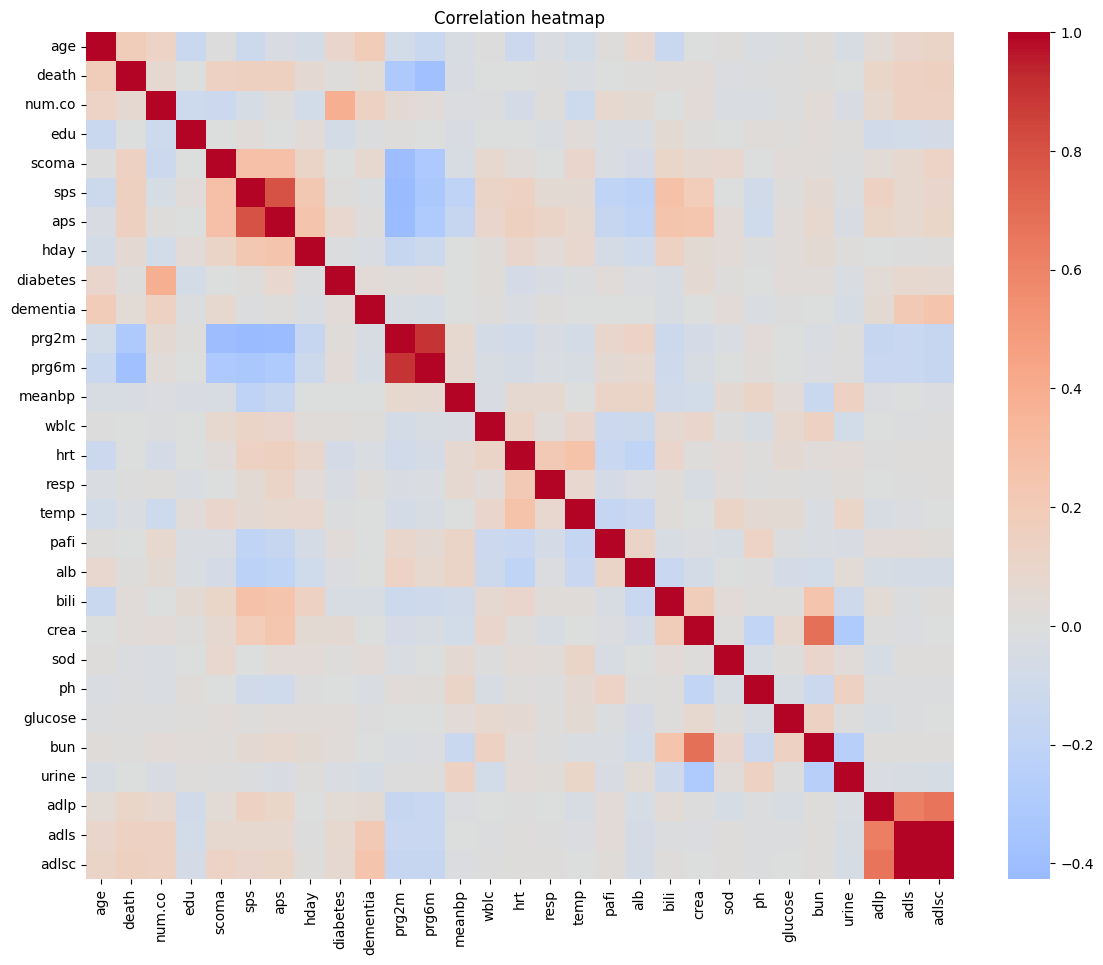

age         0.18
aps         0.16
sps         0.16
adlsc       0.15
adls        0.15
scoma       0.14
adlp        0.11
num.co      0.07
hday        0.06
dementia    0.04
bili        0.03
crea        0.03
bun         0.02
alb         0.01
diabetes    0.01
resp        0.01
glucose     0.00
pafi        0.00
edu        -0.00
hrt        -0.00
urine      -0.00
wblc       -0.00
ph         -0.01
sod        -0.02
temp       -0.03
meanbp     -0.03
prg2m      -0.31
prg6m      -0.38
Name: death, dtype: float64


In [7]:
# Sayısal sütunlar arasındaki korelasyon ısı haritası ve hedefle en ilişkili sütunlar
correlation = data.select_dtypes(include="number").corr()
plt.figure(figsize=(14, 11))
sns.heatmap(correlation, cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()
print(correlation["death"].drop("death").sort_values(ascending=False).round(2))

## 5. Drop columns with more than 50% missing values

In [8]:
# Yarısından fazlası boş olan sütunları at (doldurmak güvenilir olmaz)
high_missing_columns = missing_percent[missing_percent > 50].index
print("Dropped columns:", list(high_missing_columns))
data = data.drop(columns=high_missing_columns)

Dropped columns: ['adlp', 'urine']


## 6. Train / test split (80% / 20%)

In [9]:
# Veriyi özellikler (X) ve hedef (y) olarak ayır, sonra %80 eğitim / %20 test olarak böl
X = data.drop(columns="death")
y = data["death"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (7284, 32)  Test: (1821, 32)


## 7. Outlier detection and treatment (IQR + clip)

Limits are learned **only from the training set** and then applied to both sets.
This is done **before** filling missing values: if we filled with the median first, many identical median values would make the IQR narrower and create fake outliers.

In [10]:
# IQR sınırlarını sadece train'den hesapla, aykırı değerleri say ve iki sette de clip ile sınırla
outlier_columns = ["age", "meanbp", "wblc", "hrt", "resp", "temp", "pafi", "alb", "bili", "crea", "sod", "ph", "glucose", "bun", "sps", "aps"]
for column in outlier_columns:
    q1 = X_train[column].quantile(0.25)
    q3 = X_train[column].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    outlier_count = ((X_train[column] < lower_limit) | (X_train[column] > upper_limit)).sum()
    print(f"{column}: {outlier_count} outliers clipped to [{lower_limit:.2f}, {upper_limit:.2f}]")
    X_train[column] = X_train[column].clip(lower_limit, upper_limit)
    X_test[column] = X_test[column].clip(lower_limit, upper_limit)

age: 50 outliers clipped to [21.04, 105.91]
meanbp: 4 outliers clipped to [-3.00, 173.00]
wblc: 336 outliers clipped to [-5.30, 27.50]
hrt: 30 outliers clipped to [0.00, 192.00]
resp: 244 outliers clipped to [3.00, 43.00]
temp: 17 outliers clipped to [33.35, 40.94]
pafi: 78 outliers clipped to [-69.62, 529.38]
alb: 12 outliers clipped to [0.60, 5.40]
bili: 765 outliers clipped to [-1.60, 4.00]
crea: 781 outliers clipped to [-0.60, 3.40]
sod: 211 outliers clipped to [123.50, 151.50]
ph: 199 outliers clipped to [7.25, 7.60]
glucose: 216 outliers clipped to [-24.50, 315.50]
bun: 211 outliers clipped to [-28.00, 84.00]
sps: 230 outliers clipped to [2.20, 47.00]
aps: 184 outliers clipped to [-14.50, 85.50]


## 8. Fill missing values

In [11]:
# Eksikleri doldur: sayısal sütunlar train medyanı, kategorik sütunlar train'in en sık değeri ile
numeric_columns = X_train.select_dtypes(include="number").columns
categorical_columns = X_train.select_dtypes(include="object").columns
train_medians = X_train[numeric_columns].median()
train_modes = X_train[categorical_columns].mode().iloc[0]
X_train = X_train.fillna(train_medians).fillna(train_modes)
X_test = X_test.fillna(train_medians).fillna(train_modes)
print("Categorical columns:", list(categorical_columns))
print("Missing values left (train):", X_train.isnull().sum().sum())
print("Missing values left (test):", X_test.isnull().sum().sum())

Categorical columns: ['sex', 'dzgroup', 'dzclass', 'income', 'race', 'ca']
Missing values left (train): 0
Missing values left (test): 0


## 9. Encode categorical variables (one-hot)

In [12]:
# Kategorik sütunları get_dummies ile 0/1 sütunlara çevir, test sütunlarını train ile aynı yap
X_train = pd.get_dummies(X_train, columns=categorical_columns, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical_columns, drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print("Number of features after encoding:", X_train.shape[1])

Number of features after encoding: 46


## 10. Standardization

In [13]:
# StandardScaler: sadece train'e fit edilir, teste sadece transform uygulanır
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 11. Class balance – is SMOTE needed?

The minority class (survived) is about **32%** of the data, so the classes are only mildly imbalanced (about 2 : 1).
This is not a severe imbalance, so **SMOTE is not used**: creating synthetic patients could add noise, and the models can still learn both classes well.
We also report Recall, Specificity, Balanced Accuracy and MCC, which show if a model ignores the smaller class.

In [14]:
# Eğitim setindeki sınıf oranlarını kontrol et
print(y_train.value_counts(normalize=True).round(3))

death
1    0.681
0    0.319
Name: proportion, dtype: float64


## 12. Modeling – GridSearchCV with 5-fold cross-validation

Each model is tuned with a small parameter grid. GridSearchCV tries every combination with 5-fold CV on the training set and chooses the one with the best ROC-AUC.

In [15]:
# Her model ve denenecek küçük parametre ızgarası
models_and_grids = {
    "Decision Tree": (DecisionTreeClassifier(random_state=42), {"max_depth": [3, 5, 8, 12], "min_samples_leaf": [1, 10, 30]}),
    "Naive Bayes": (GaussianNB(), {"var_smoothing": [1e-9, 1e-7, 1e-5]}),
    "SVM": (SVC(probability=True, random_state=42), {"C": [0.1, 1, 10], "gamma": ["scale", 0.01]}),
    "MLP": (MLPClassifier(max_iter=500, random_state=42), {"hidden_layer_sizes": [(32,), (64, 32)], "alpha": [0.0001, 0.01]}),
    "Random Forest": (RandomForestClassifier(random_state=42), {"n_estimators": [100, 300], "max_depth": [None, 10]}),
    "Logistic Regression": (LogisticRegression(max_iter=1000), {"C": [0.01, 0.1, 1, 10]}),
}

In [16]:
# Her modeli GridSearchCV (5-fold) ile eğit, en iyi parametreleri ve CV skorunu yazdır
best_models = {}
for model_name, (model, parameter_grid) in models_and_grids.items():
    grid_search = GridSearchCV(model, parameter_grid, cv=5, scoring="roc_auc", n_jobs=-1)
    grid_search.fit(X_train_scaled, y_train)
    best_models[model_name] = grid_search.best_estimator_
    print(f"{model_name}: best params = {grid_search.best_params_}, CV ROC-AUC = {grid_search.best_score_:.3f}")

Decision Tree: best params = {'max_depth': 5, 'min_samples_leaf': 30}, CV ROC-AUC = 0.753
Naive Bayes: best params = {'var_smoothing': 1e-09}, CV ROC-AUC = 0.743


SVM: best params = {'C': 0.1, 'gamma': 0.01}, CV ROC-AUC = 0.796


MLP: best params = {'alpha': 0.01, 'hidden_layer_sizes': (32,)}, CV ROC-AUC = 0.744


Random Forest: best params = {'max_depth': 10, 'n_estimators': 300}, CV ROC-AUC = 0.801


Logistic Regression: best params = {'C': 0.01}, CV ROC-AUC = 0.800


## 13. Evaluation on the test set

In [17]:
# Her model için test setinde tüm metrikleri hesapla ve tek bir karşılaştırma tablosunda göster
results = []
for model_name, model in best_models.items():
    y_pred = model.predict(X_test_scaled)
    y_probability = model.predict_proba(X_test_scaled)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_probability),
        "Specificity": tn / (tn + fp),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "Cohen Kappa": cohen_kappa_score(y_test, y_pred),
        "Balanced Acc.": balanced_accuracy_score(y_test, y_pred),
    })
results_table = pd.DataFrame(results).set_index("Model").round(3)
results_table.sort_values("ROC-AUC", ascending=False)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Specificity,MCC,Cohen Kappa,Balanced Acc.
Model,,,,,,,,,
Logistic Regression,0.759,0.785,0.890,0.834,0.816,0.478,0.410,0.399,0.684
SVM,0.751,0.750,0.951,0.839,0.812,0.324,0.372,0.324,0.637
Random Forest,0.754,0.765,0.922,0.836,0.810,0.396,0.386,0.359,0.659
Naive Bayes,0.666,0.869,0.599,0.709,0.760,0.807,0.380,0.346,0.703
Decision Tree,0.739,0.775,0.870,0.820,0.758,0.460,0.362,0.355,0.665
MLP,0.714,0.768,0.832,0.799,0.743,0.463,0.313,0.310,0.648


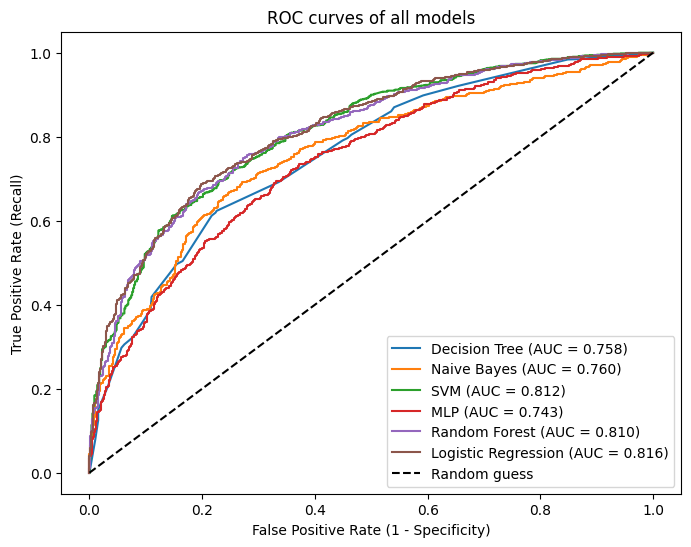

In [18]:
# Tüm modellerin ROC eğrilerini tek grafikte çiz
plt.figure(figsize=(8, 6))
for model_name, model in best_models.items():
    y_probability = model.predict_proba(X_test_scaled)[:, 1]
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, y_probability)
    plt.plot(false_positive_rate, true_positive_rate, label=f"{model_name} (AUC = {results_table.loc[model_name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curves of all models")
plt.legend()
plt.show()

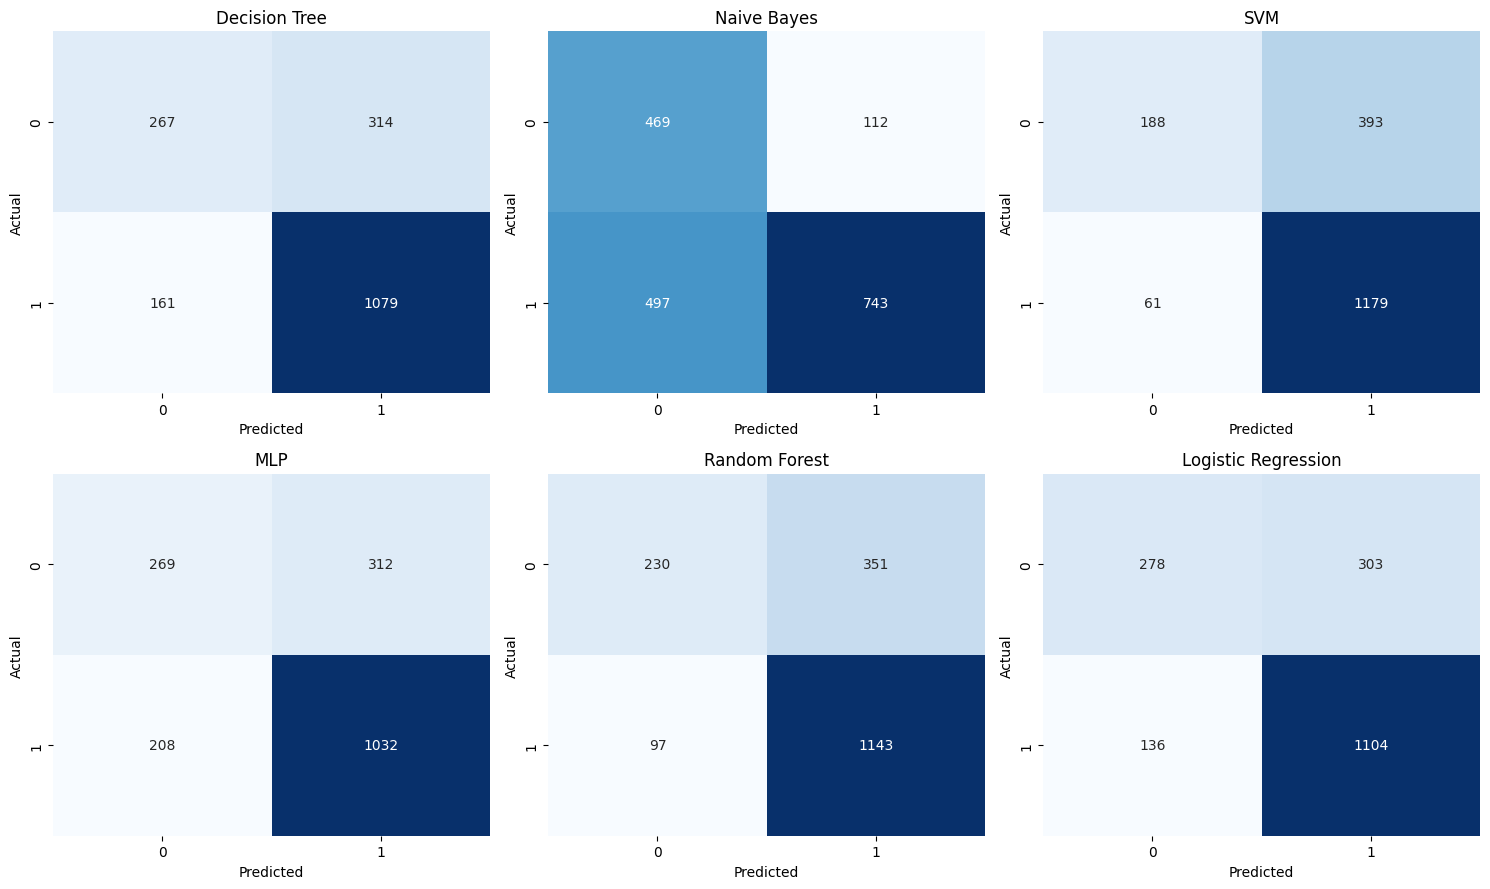

In [19]:
# Her model için confusion matrix çiz (satır = gerçek, sütun = tahmin)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for axis, (model_name, model) in zip(axes.flatten(), best_models.items()):
    matrix = confusion_matrix(y_test, model.predict(X_test_scaled))
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis)
    axis.set_title(model_name)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")
plt.tight_layout()
plt.show()

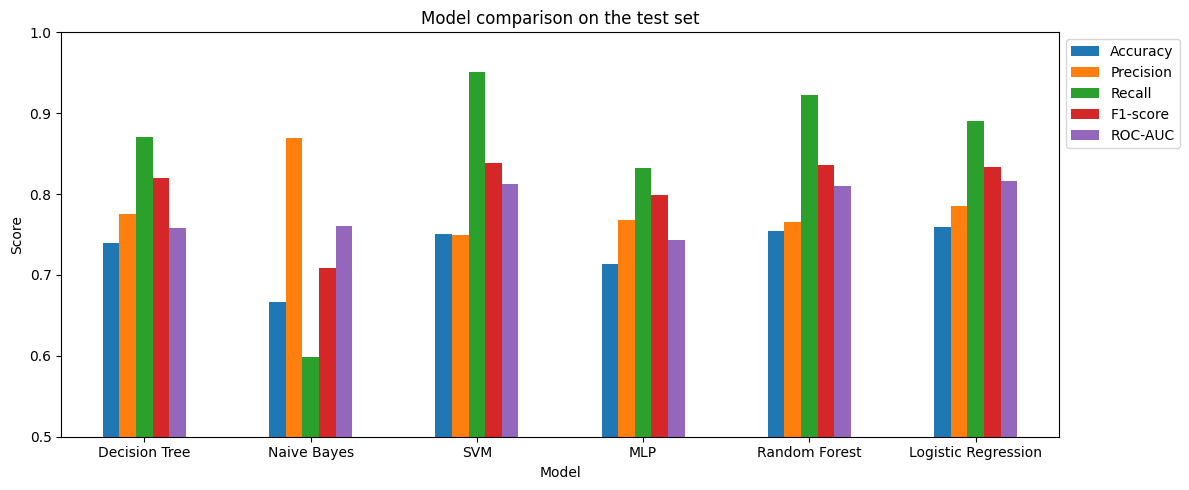

In [20]:
# Ana metrikleri modellere göre bar grafiğiyle karşılaştır
results_table[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(kind="bar", figsize=(12, 5))
plt.ylim(0.5, 1)
plt.ylabel("Score")
plt.title("Model comparison on the test set")
plt.xticks(rotation=0)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 14. Most influential features (Random Forest)

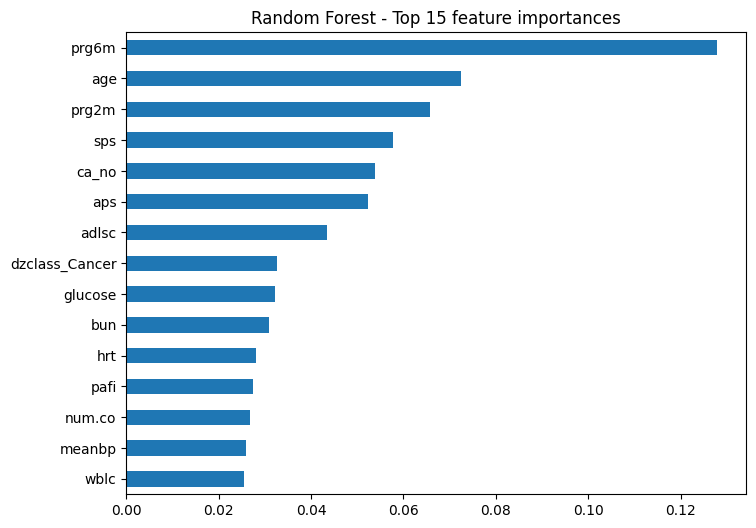

prg6m             0.128
age               0.073
prg2m             0.066
sps               0.058
ca_no             0.054
aps               0.052
adlsc             0.044
dzclass_Cancer    0.033
glucose           0.032
bun               0.031
dtype: float64


In [21]:
# Random Forest'a göre en önemli 15 özelliği çiz ve ilk 10'unu yazdır
feature_importance = pd.Series(best_models["Random Forest"].feature_importances_, index=X_train.columns)
feature_importance.sort_values().tail(15).plot(kind="barh", figsize=(8, 6))
plt.title("Random Forest - Top 15 feature importances")
plt.show()
print(feature_importance.sort_values(ascending=False).head(10).round(3))

## 15. Results summary

- **Best model: Logistic Regression** – test ROC-AUC 0.816, Accuracy 0.759, F1 0.834, MCC 0.410. SVM (0.812) and Random Forest (0.810) are very close.
- All models find patients who die well (Recall 0.83–0.95) but recognise survivors less well (Specificity 0.32–0.48). Naive Bayes is the opposite: Specificity 0.807 but Recall only 0.599.
- The most influential features are the doctor's survival estimates (`prg6m`, `prg2m`), age, illness severity scores (`sps`, `aps`), cancer status and daily-living activity score.